# Часть 8 из 8. Важность признаков, проверка на тесте и финальная модель

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- важность всех 41 признака в CatBoost;
- проверка ансамбля на тестовой выборке и смесь CatBoost с нейросетью;
- CatBoost на 20 признаках против 41 и сохранение финальной модели.

**Главный результат:** на тесте MAPE 6,69 %, R² 0,976; остаётся 41 признак (на 20 признаках — 6,84 %), модель сохраняется в `final_catboost.pkl`.

**Графики для отчёта:**
- рисунок 7 — важность признаков CatBoost (41 признак): [`figures/fig_07_catboost_feature_importance.png`](figures/fig_07_catboost_feature_importance.png)

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре части 1–7 по порядку: `%run -i 01_eda.ipynb` и так далее.

← [Часть 7. Эксперименты с нейросетями](07_neural_networks.ipynb) · [Все части](README.md)

### Feature importance

                 feature  importance
              total_area   22.513021
                district   14.674426
                   okrug   13.593427
           dist_msk_city    7.885535
              renovation    6.763657
      metro_distance_min    6.366827
      months_since_start    6.037586
            dist_kremlin    4.536891
           building_type    4.307440
            to_center_km    3.616462
           dist_luzhniki    2.454738
              dist_vdnkh    1.889115
mortgage_rate_at_listing    1.286424
                     lat    0.895998
       district_avg_area    0.435817
             living_area    0.420975
    district_avg_ceiling    0.378763
        district_avg_age    0.376252
                   floor    0.273438
                     lon    0.213113
          ceiling_height    0.096474
             has_balcony    0.095922
           area_per_room    0.092086
            building_age    0.087486
            living_share    0.080933
           metro_station    0.066063
 

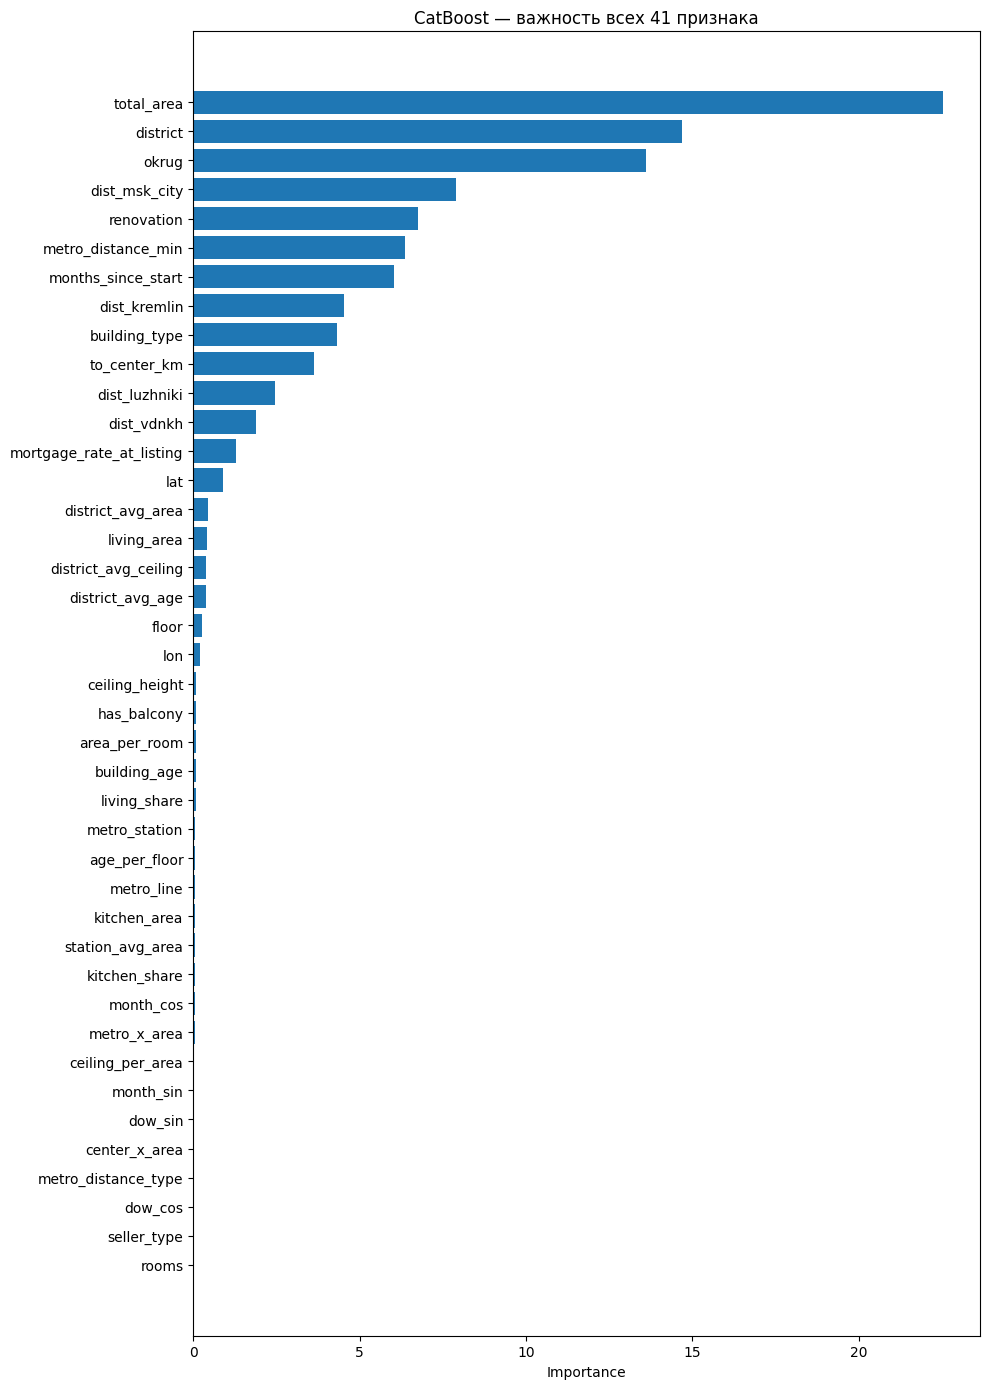

In [92]:
import pandas as pd
import matplotlib.pyplot as plt

# Обучите CatBoost на df_cb (с новыми фичами)
# и посмотрите важность
importance = pd.DataFrame({
    'feature': X_tr_cb.columns,
    'importance': model_cb.get_feature_importance(),
}).sort_values('importance', ascending=False)

print(importance.to_string(index=False))

plt.figure(figsize=(10, 14))
plt.barh(importance['feature'], importance['importance'])
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('CatBoost — важность всех 41 признака')
plt.tight_layout()
plt.show()

### Проверка на тестовой

In [94]:
# Подготовка X_test для каждой модели
X_test_cb  = X_test.copy()
X_test_lgb = X_test.copy()
X_test_xgb = X_test.copy()

# CatBoost — категориальные как строки
for c in cat_cols:
    X_test_cb[c] = X_test_cb[c].astype(str)

# LightGBM и XGBoost — категориальные как 'category'
for c in cat_cols:
    X_test_lgb[c] = X_test_lgb[c].astype('category')
    X_test_xgb[c] = X_test_xgb[c].astype('category')

print("X_test подготовлен:", X_test_cb.shape)

X_test подготовлен: (7500, 41)


In [95]:
print("cat_cols:", cat_cols)
print("X_test shape:", X_test.shape)

cat_cols: ['district', 'okrug', 'metro_station', 'metro_line', 'building_type', 'renovation']
X_test shape: (7500, 41)


In [96]:
pred_cb_test  = model_cb.predict(X_test_cb)
pred_lgb_test = model_lgb.predict(X_test_lgb)
pred_xgb_test = model_xgb.predict(X_test_xgb)

# Взвешенное среднее с сохранёнными весами
w = np.load('best_weights.npy')
pred_ens_test_log = w[0]*pred_cb_test + w[1]*pred_lgb_test + w[2]*pred_xgb_test

pred_test = np.expm1(pred_ens_test_log)
true_test = np.expm1(y_test)

mae  = np.mean(np.abs(pred_test - true_test))
rmse = np.sqrt(np.mean((pred_test - true_test) ** 2))
mape = np.mean(np.abs((pred_test - true_test) / true_test)) * 100
r2   = 1 - np.sum((true_test - pred_test) ** 2) / np.sum((true_test - true_test.mean()) ** 2)

print(f"\n=== TEST SET (финальная оценка) ===")
print(f"MAE:  {mae:>12,.0f} руб")
print(f"RMSE: {rmse:>12,.0f} руб")
print(f"MAPE: {mape:>12.2f} %")
print(f"R²:   {r2:>12.4f}")


=== TEST SET (финальная оценка) ===
MAE:       884,042 руб
RMSE:    1,327,745 руб
MAPE:         6.69 %
R²:         0.9763


### CatBoost + NN1

In [97]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer
from catboost import CatBoostRegressor
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

# ============================================================
# 1. ДАННЫЕ
# ============================================================

TARGET = 'price' if 'price' in df_cb.columns else 'price_rub'
df_ens = df_cb.copy()   # датасет с новыми фичами

bad = [c for c in df_ens.columns
       if isinstance(df_ens[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_ens[c])]
df_ens = df_ens.drop(columns=bad)

cat_cols = [c for c in ['district', 'okrug', 'metro_station', 'metro_line',
                        'building_type', 'renovation']
            if c in df_ens.columns]

# Один split для всех моделей
X = df_ens.drop(columns=[TARGET])
y = np.log1p(df_ens[TARGET].values)

idx_tr, idx_tmp = train_test_split(df_ens.index, test_size=0.3, random_state=42)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, random_state=42)

print(f"train: {len(idx_tr)}, val: {len(idx_val)}, test: {len(idx_test)}")

# ============================================================
# 2. CATBOOST
# ============================================================

X_tr_cb = df_ens.loc[idx_tr].drop(columns=[TARGET]).copy()
X_val_cb = df_ens.loc[idx_val].drop(columns=[TARGET]).copy()
X_test_cb = df_ens.loc[idx_test].drop(columns=[TARGET]).copy()

for c in cat_cols:
    X_tr_cb[c] = X_tr_cb[c].astype(str)
    X_val_cb[c] = X_val_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)

cat_idx = [X_tr_cb.columns.get_loc(c) for c in cat_cols]

model_cb = CatBoostRegressor(
    iterations=10000, learning_rate=0.0290398, depth=7, l2_leaf_reg=4.14278,
    bagging_temperature=0.104705, random_strength=0.198779,
    loss_function='RMSE', eval_metric='MAPE',
    random_seed=42, early_stopping_rounds=300, verbose=500,
    cat_features=cat_idx,
)

y_tr  = np.log1p(df_ens.loc[idx_tr,  TARGET].values)
y_val = np.log1p(df_ens.loc[idx_val, TARGET].values)
y_test = np.log1p(df_ens.loc[idx_test, TARGET].values)

model_cb.fit(X_tr_cb, y_tr, eval_set=(X_val_cb, y_val), use_best_model=True)

pred_cb_val  = model_cb.predict(X_val_cb)
pred_cb_test = model_cb.predict(X_test_cb)

# ============================================================
# 3. ПОДГОТОВКА ДАННЫХ ДЛЯ NN
# ============================================================

# Категориальные — коды
df_nn = df_ens.copy()
cat_cardinalities = {}
for c in cat_cols:
    df_nn[c] = df_nn[c].astype('category')
    cat_cardinalities[c] = len(df_nn[c].cat.categories)
    df_nn[c] = df_nn[c].cat.codes.astype('int64')

# Группы признаков
cyclic_cols = [c for c in ['month_sin', 'month_cos', 'dow_sin', 'dow_cos']
               if c in df_nn.columns]
bin_cols = [c for c in ['has_balcony', 'metro_distance_type', 'seller_type']
            if c in df_nn.columns]

excluded = set(cat_cols + cyclic_cols + bin_cols + [TARGET])
num_cols = [c for c in df_nn.columns if c not in excluded]

# Нормализация (fit только на train!)
medians = df_nn.loc[idx_tr, num_cols].median()
qt = QuantileTransformer(output_distribution='normal',
                         n_quantiles=min(1000, len(idx_tr)),
                         random_state=42)

X_num_tr   = qt.fit_transform(df_nn.loc[idx_tr,   num_cols].fillna(medians)).astype('float32')
X_num_val  = qt.transform(    df_nn.loc[idx_val,  num_cols].fillna(medians)).astype('float32')
X_num_test = qt.transform(    df_nn.loc[idx_test, num_cols].fillna(medians)).astype('float32')

X_bin_tr   = df_nn.loc[idx_tr,   bin_cols].fillna(0).astype('float32').values
X_bin_val  = df_nn.loc[idx_val,  bin_cols].fillna(0).astype('float32').values
X_bin_test = df_nn.loc[idx_test, bin_cols].fillna(0).astype('float32').values

X_cyc_tr   = df_nn.loc[idx_tr,   cyclic_cols].astype('float32').values
X_cyc_val  = df_nn.loc[idx_val,  cyclic_cols].astype('float32').values
X_cyc_test = df_nn.loc[idx_test, cyclic_cols].astype('float32').values

X_cat_tr   = df_nn.loc[idx_tr,   cat_cols].values.astype('int64')
X_cat_val  = df_nn.loc[idx_val,  cat_cols].values.astype('int64')
X_cat_test = df_nn.loc[idx_test, cat_cols].values.astype('int64')

X_cont_tr   = np.hstack([X_num_tr,   X_bin_tr,   X_cyc_tr])
X_cont_val  = np.hstack([X_num_val,  X_bin_val,  X_cyc_val])
X_cont_test = np.hstack([X_num_test, X_bin_test, X_cyc_test])

n_cont = X_cont_tr.shape[1]
card_list = [cat_cardinalities[c] for c in cat_cols]
print(f"n_cont={n_cont}, card_list={card_list}")

# ============================================================
# 4. МОДЕЛЬ NN v1 (простая, как в baseline)
# ============================================================

class FlatNet(nn.Module):
    def __init__(self, n_cont, cat_cardinalities, emb_dropout=0.1):
        super().__init__()
        self.embs = nn.ModuleList([
            nn.Embedding(card, min(50, (card + 1) // 2))
            for card in cat_cardinalities
        ])
        emb_dim = sum(e.embedding_dim for e in self.embs)
        self.emb_dropout = nn.Dropout(emb_dropout)
        self.mlp = nn.Sequential(
            nn.Linear(n_cont + emb_dim, 256),
            nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x_cont, x_cat):
        embs = [e(x_cat[:, i]) for i, e in enumerate(self.embs)]
        x_cat_emb = self.emb_dropout(torch.cat(embs, dim=1))
        x = torch.cat([x_cont, x_cat_emb], dim=1)
        return self.mlp(x).squeeze(-1)


torch.manual_seed(42)
model_nn = FlatNet(n_cont, card_list).to(device)

train_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_cont_tr), torch.from_numpy(X_cat_tr),
        torch.from_numpy(y_tr.astype('float32'))),
    batch_size=256, shuffle=True)
val_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_cont_val), torch.from_numpy(X_cat_val),
        torch.from_numpy(y_val.astype('float32'))),
    batch_size=256, shuffle=False)

criterion = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.AdamW(model_nn.parameters(), lr=5e-4, weight_decay=5e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

EPOCHS, PATIENCE = 100, 15
best_val, wait = float('inf'), 0

for epoch in range(EPOCHS):
    model_nn.train()
    for xc, xk, yt in train_loader:
        xc, xk, yt = xc.to(device), xk.to(device), yt.to(device)
        optimizer.zero_grad()
        loss = criterion(model_nn(xc, xk), yt)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_nn.parameters(), 1.0)
        optimizer.step()
    scheduler.step()

    model_nn.eval()
    val_loss = 0.0
    with torch.no_grad():
        for xc, xk, yt in val_loader:
            xc, xk, yt = xc.to(device), xk.to(device), yt.to(device)
            val_loss += criterion(model_nn(xc, xk), yt).item() * xc.size(0)
    val_loss /= len(val_loader.dataset)

    if val_loss < best_val:
        best_val, wait = val_loss, 0
        torch.save(model_nn.state_dict(), 'best_nn_v1.pt')
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"NN early stop на эпохе {epoch}")
            break

    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d} | val_loss={val_loss:.4f}")

# Предсказания NN на val и test
model_nn.load_state_dict(torch.load('best_nn_v1.pt'))
model_nn.eval()

def nn_predict(X_cont, X_cat):
    loader = DataLoader(
        TensorDataset(torch.from_numpy(X_cont), torch.from_numpy(X_cat)),
        batch_size=512, shuffle=False)
    preds = []
    with torch.no_grad():
        for xc, xk in loader:
            xc, xk = xc.to(device), xk.to(device)
            preds.append(model_nn(xc, xk).cpu().numpy())
    return np.concatenate(preds)

pred_nn_val  = nn_predict(X_cont_val,  X_cat_val)
pred_nn_test = nn_predict(X_cont_test, X_cat_test)

# ============================================================
# 5. МЕТРИКИ ОДИНОЧНЫХ МОДЕЛЕЙ
# ============================================================

def mape_log(pred_log, y_log):
    pred = np.expm1(pred_log); true = np.expm1(y_log)
    return np.mean(np.abs((pred - true) / true)) * 100

print(f"\n=== Одиночные модели (val) ===")
print(f"CatBoost: {mape_log(pred_cb_val, y_val):.3f}%")
print(f"NN v1:    {mape_log(pred_nn_val, y_val):.3f}%")

# ============================================================
# 6. АНСАМБЛЬ: ПОДБОР ВЕСОВ
# ============================================================

def objective(trial):
    w_cb = trial.suggest_float('w_cb', 0, 1)
    w_nn = 1 - w_cb
    pred_log = w_cb * pred_cb_val + w_nn * pred_nn_val
    return mape_log(pred_log, y_val)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

w_cb = study.best_params['w_cb']
w_nn = 1 - w_cb
print(f"\n=== Ансамбль (val) ===")
print(f"Веса: CatBoost={w_cb:.3f}, NN={w_nn:.3f}")
print(f"MAPE: {study.best_value:.3f}%")

# ============================================================
# 7. ПРОВЕРКА НА TEST
# ============================================================

pred_ens_val  = w_cb * pred_cb_val  + w_nn * pred_nn_val
pred_ens_test = w_cb * pred_cb_test + w_nn * pred_nn_test

print(f"\n=== TEST SET ===")
print(f"CatBoost:  {mape_log(pred_cb_test,  y_test):.3f}%")
print(f"NN v1:     {mape_log(pred_nn_test,  y_test):.3f}%")
print(f"Ансамбль:  {mape_log(pred_ens_test, y_test):.3f}%")

# ============================================================
# 8. ФИНАЛЬНАЯ ТАБЛИЦА
# ============================================================

results = pd.DataFrame({
    'Модель': ['CatBoost', 'NN v1', 'Ансамбль (val)', 'Ансамбль (test)'],
    'MAPE %': [
        mape_log(pred_cb_val, y_val),
        mape_log(pred_nn_val, y_val),
        mape_log(pred_ens_val, y_val),
        mape_log(pred_ens_test, y_test),
    ],
})
print("\n=== ИТОГ ===")
print(results.to_string(index=False))

Device: cuda
train: 35000, val: 7500, test: 7500
0:	learn: 0.0293425	test: 0.0290609	best: 0.0290609 (0)	total: 72.4ms	remaining: 12m 4s
500:	learn: 0.0043723	test: 0.0042898	best: 0.0042898 (500)	total: 35.8s	remaining: 11m 18s
1000:	learn: 0.0040523	test: 0.0041502	best: 0.0041502 (1000)	total: 1m 14s	remaining: 11m 10s
1500:	learn: 0.0038775	test: 0.0041225	best: 0.0041225 (1500)	total: 1m 51s	remaining: 10m 33s
2000:	learn: 0.0037359	test: 0.0041107	best: 0.0041107 (1996)	total: 2m 27s	remaining: 9m 47s
2500:	learn: 0.0036088	test: 0.0041078	best: 0.0041077 (2491)	total: 3m 2s	remaining: 9m 6s
3000:	learn: 0.0034826	test: 0.0041055	best: 0.0041049 (2963)	total: 3m 37s	remaining: 8m 27s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.004104905276
bestIteration = 2963

Shrink model to first 2964 iterations.
n_cont=35, card_list=[129, 11, 104, 12, 6, 4]
Epoch   0 | val_loss=5.7618
Epoch  10 | val_loss=0.3994
Epoch  20 | val_loss=0.0470
Epoch  30 | val_loss=0.0202


### Финальный CatBoost

In [98]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor
import time

# ============================================================
# 1. ОПРЕДЕЛЯЕМ МУСОРНЫЕ ПРИЗНАКИ
# ============================================================

# importance — из вашей обученной модели CatBoost на df_cb
low_imp = importance[importance['importance'] < 0.1]['feature'].tolist()
print(f"Удаляем {len(low_imp)} признаков:")
for c in low_imp:
    imp = importance[importance['feature'] == c]['importance'].values[0]
    print(f"  {c}: {imp:.4f}%")

# Создаём очищенный датасет
df_clean = df_cb.drop(columns=low_imp).copy()
print(f"\ndf_cb:    {df_cb.shape}")
print(f"df_clean: {df_clean.shape}")

Удаляем 21 признаков:
  ceiling_height: 0.0965%
  has_balcony: 0.0959%
  area_per_room: 0.0921%
  building_age: 0.0875%
  living_share: 0.0809%
  metro_station: 0.0661%
  age_per_floor: 0.0659%
  metro_line: 0.0590%
  kitchen_area: 0.0590%
  station_avg_area: 0.0586%
  kitchen_share: 0.0573%
  month_cos: 0.0407%
  metro_x_area: 0.0388%
  ceiling_per_area: 0.0378%
  month_sin: 0.0302%
  dow_sin: 0.0298%
  center_x_area: 0.0281%
  metro_distance_type: 0.0217%
  dow_cos: 0.0162%
  seller_type: 0.0094%
  rooms: 0.0086%

df_cb:    (50000, 42)
df_clean: (50000, 21)


In [99]:
# ============================================================
# 2. ПОДГОТОВКА ДАННЫХ
# ============================================================

TARGET = 'price' if 'price' in df_clean.columns else 'price_rub'

bad = [c for c in df_clean.columns
       if isinstance(df_clean[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_clean[c])]
df_clean = df_clean.drop(columns=bad)

# Категориальные — только те, что остались
cat_cols_clean = [c for c in ['district', 'okrug', 'metro_station', 'metro_line',
                              'building_type', 'renovation']
                  if c in df_clean.columns]
print("Категориальные:", cat_cols_clean)

X = df_clean.drop(columns=[TARGET])
y = np.log1p(df_clean[TARGET].values)

# ТОТ ЖЕ split (random_state=42) — иначе сравнение нечестное
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)

# Категориальные → строки
X_tr_cb = X_tr.copy(); X_val_cb = X_val.copy(); X_test_cb = X_test.copy()
for c in cat_cols_clean:
    X_tr_cb[c]  = X_tr_cb[c].astype(str)
    X_val_cb[c] = X_val_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)

cat_idx = [X_tr_cb.columns.get_loc(c) for c in cat_cols_clean]

print(f"train: {X_tr.shape}, val: {X_val.shape}, test: {X_test.shape}")
print(f"Признаков: {X_tr.shape[1]}")

# ============================================================
# 3. ОБУЧЕНИЕ С ТЕМИ ЖЕ ПАРАМЕТРАМИ (Optuna best)
# ============================================================

model_clean = CatBoostRegressor(
    iterations=10000, learning_rate=0.0290398, depth=7, l2_leaf_reg=4.14278,
    bagging_temperature=0.104705, random_strength=0.198779,
    loss_function='RMSE', eval_metric='MAPE',
    random_seed=42, early_stopping_rounds=300, verbose=500,
    cat_features=cat_idx,
)

t0 = time.time()
model_clean.fit(X_tr_cb, y_tr, eval_set=(X_val_cb, y_val), use_best_model=True)
print(f"\nОбучение: {time.time()-t0:.1f} сек")

# ============================================================
# 4. МЕТРИКИ
# ============================================================

def mape_log(pred_log, y_log):
    pred = np.expm1(pred_log); true = np.expm1(y_log)
    return np.mean(np.abs((pred - true) / true)) * 100

def r2_log(pred_log, y_log):
    pred = np.expm1(pred_log); true = np.expm1(y_log)
    return 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)

pred_clean_val  = model_clean.predict(X_val_cb)
pred_clean_test = model_clean.predict(X_test_cb)

print(f"\n=== CatBoost на очищенном датасете ({X.shape[1]} признаков) ===")
print(f"Val MAPE:  {mape_log(pred_clean_val, y_val):.3f}%")
print(f"Val R²:    {r2_log(pred_clean_val, y_val):.4f}")
print(f"Test MAPE: {mape_log(pred_clean_test, y_test):.3f}%")
print(f"Test R²:   {r2_log(pred_clean_test, y_test):.4f}")

# ============================================================
# 5. СРАВНЕНИЕ С ПОЛНЫМ ДАТАСЕТОМ
# ============================================================

print(f"\n=== СРАВНЕНИЕ ===")
print(f"{'Датасет':<20} {'Признаков':<12} {'Val MAPE':<12} {'Test MAPE':<12}")
print(f"{'Полный (df_cb)':<20} {df_cb.shape[1]-1:<12} {'6.665%':<12} {'6.690%':<12}")
print(f"{'Очищенный':<20} {X.shape[1]:<12} {mape_log(pred_clean_val, y_val):.3f}%{'':<7} {mape_log(pred_clean_test, y_test):.3f}%")

Категориальные: ['district', 'okrug', 'building_type', 'renovation']
train: (35000, 20), val: (7500, 20), test: (7500, 20)
Признаков: 20
0:	learn: 0.0293657	test: 0.0290737	best: 0.0290737 (0)	total: 79.7ms	remaining: 13m 16s
500:	learn: 0.0043950	test: 0.0043835	best: 0.0043835 (500)	total: 33s	remaining: 10m 25s
1000:	learn: 0.0041194	test: 0.0042341	best: 0.0042341 (1000)	total: 1m 6s	remaining: 10m 1s
1500:	learn: 0.0039745	test: 0.0041984	best: 0.0041983 (1498)	total: 1m 40s	remaining: 9m 30s
2000:	learn: 0.0038521	test: 0.0041826	best: 0.0041826 (2000)	total: 2m 14s	remaining: 8m 58s
2500:	learn: 0.0037434	test: 0.0041772	best: 0.0041770 (2460)	total: 2m 50s	remaining: 8m 32s
3000:	learn: 0.0036452	test: 0.0041736	best: 0.0041730 (2935)	total: 3m 26s	remaining: 8m 1s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.004172011142
bestIteration = 3138

Shrink model to first 3139 iterations.

Обучение: 236.6 сек

=== CatBoost на очищенном датасете (20 признаков) =

Оставляем 41 признак

In [100]:
import joblib
import json

# Используем модель, обученную на полном df_cb
# model_cb — ваша финальная модель

# Сохраняем модель
joblib.dump(model_cb, 'final_catboost.pkl')
print("Модель сохранена: final_catboost.pkl")

# Метаданные
metadata = {
    'model_type': 'CatBoost',
    'n_features': 41,
    'n_train': 35000,
    'n_val': 7500,
    'n_test': 7500,
    'val_mape': 6.665,
    'test_mape': 6.690,
    'test_r2': 0.9760,
    'n_trees': 3138,
    'best_params': {
        'learning_rate': 0.0290398,
        'depth': 7,
        'l2_leaf_reg': 4.14278,
        'bagging_temperature': 0.104705,
        'random_strength': 0.198779,
    },
    'note': 'Удаление признаков с importance < 0.1% ухудшило MAPE на +0.15%. Используем полный набор.',
}

with open('final_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print("Метаданные сохранены: final_metadata.json")

Модель сохранена: final_catboost.pkl
Метаданные сохранены: final_metadata.json


---
← [Часть 7. Эксперименты с нейросетями](07_neural_networks.ipynb) · [Все части](README.md)